# Eksplorasi Data (EDA) - Dataset Abalone
Tugas Kelompok 2 (Topik 2: Model Prediktif sebagai Cloud API)

Di notebook ini saya melakukan pengecekan awal terhadap dataset Abalone sebelum masuk ke tahap *preprocessing* dan pemodelan. Target yang mau diprediksi adalah `Rings` (jumlah cincin cangkang, yang kalau ditambah 1.5 jadi estimasi umur abalone dalam tahun).

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
os.makedirs("docs/evidence", exist_ok=True)

In [18]:
kolom = [
    "Sex", "Length", "Diameter", "Height",
    "Whole weight", "Shucked weight", "Viscera weight", "Shell weight", "Rings"
]

def ambil_file_manual():
    lokasi_file = None
    try:
        from google.colab import files
        print("Silakan pilih file dataset lewat tombol Choose Files:")
        diupload = files.upload()
        if diupload:
            lokasi_file = list(diupload.keys())[0]
    except ImportError:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        lokasi_file = filedialog.askopenfilename(
            title="Pilih file dataset Abalone",
            filetypes=[
                ("File Dataset", "*.xlsx *.xls *.csv *.data"),
                ("Semua File", "*.*")
            ]
        )
        root.destroy()

    if not lokasi_file:
        raise ValueError("Belum ada file yang dipilih. Jalankan ulang sel ini untuk memilih file.")

    print("File yang dipilih:", lokasi_file)
    if lokasi_file.endswith((".xlsx", ".xls")):
        xls = pd.ExcelFile(lokasi_file)
        nama_sheet = "Dataset_Abalone" if "Dataset_Abalone" in xls.sheet_names else xls.sheet_names[0]
        return pd.read_excel(lokasi_file, sheet_name=nama_sheet)
    elif lokasi_file.endswith(".csv"):
        return pd.read_csv(lokasi_file)
    else:
        return pd.read_csv(lokasi_file, header=None, names=kolom)

df = ambil_file_manual()
print("Ukuran data:", df.shape)
df.head(10)

File yang dipilih: C:/Users/DELL/Downloads/Dataset_Abalone_Lengkap.xlsx
Ukuran data: (4177, 9)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16
8,M,0.475,0.370,0.125,0.5095,0.2165,0.1125,0.165,9
9,F,0.550,0.440,0.150,0.8945,0.3145,0.1510,0.320,19


### Cek Info, Missing Value, dan Duplikat

In [19]:
df.info()
print("\nJumlah missing value per kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB

Jumlah missing value per kolom:
Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Shucked weight    0
Viscera weight    0
Shell weight      0
Rings             0
dtype: int64

Jumlah baris duplikat: 0


In [20]:
# Ringkasan statistik deskriptif
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


# Cek baris yang nilai Height-nya 0 karena tadi terlihat nilai minimumnya 0.000

In [21]:
df[df["Height"] == 0]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


Dari pengecekan data:
- Ada 4.177 baris dan 9 kolom, tanpa *missing value* dan tanpa baris duplikat.
- Ada 2 data dengan `Height = 0` (kemungkinan salah catat saat pengukuran), tapi barisnya tetap dipertahankan dulu dan di *pipeline* preprocessing tetap dipasangkan `SimpleImputer` untuk mengantisipasi data baru dari API.

### Sebaran Target (`Rings`) dan Perbandingan per Kategori `Sex`

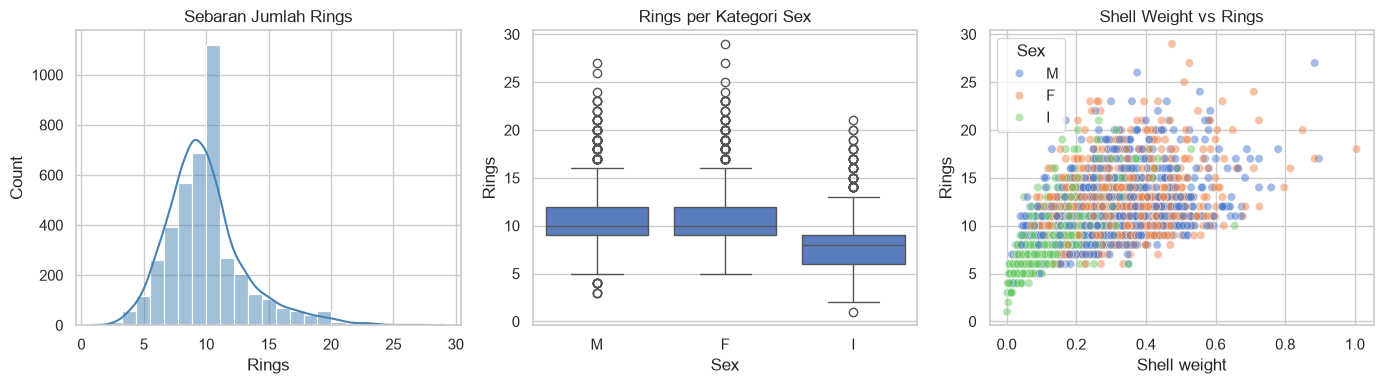

In [22]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.histplot(df["Rings"], bins=25, kde=True, color="steelblue")
plt.title("Sebaran Jumlah Rings")
plt.xlabel("Rings")

plt.subplot(1, 3, 2)
sns.boxplot(data=df, x="Sex", y="Rings", order=["M", "F", "I"])
plt.title("Rings per Kategori Sex")

plt.subplot(1, 3, 3)
sns.scatterplot(data=df, x="Shell weight", y="Rings", hue="Sex", alpha=0.5)
plt.title("Shell Weight vs Rings")

plt.tight_layout()
plt.savefig("docs/evidence/eda_distribusi_target.png", dpi=150)
plt.show()

### Korelasi Antar Variabel Numerik

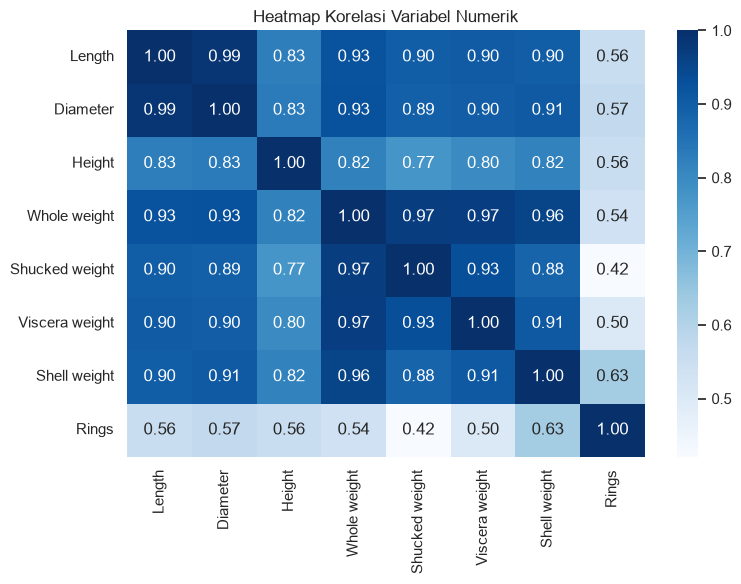

In [23]:
plt.figure(figsize=(8, 6))
korelasi = df.drop(columns=["Sex"]).corr()
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="Blues")
plt.title("Heatmap Korelasi Variabel Numerik")
plt.tight_layout()
plt.savefig("docs/evidence/eda_korelasi.png", dpi=150)
plt.show()

`Shell weight` memiliki korelasi paling tinggi terhadap `Rings` (0.63), diikuti `Diameter` (0.57) dan `Length` (0.56). Variabel ukuran fisik juga saling berkorelasi cukup kuat, sehingga model seperti Random Forest dan Ridge relevan untuk diuji.

In [25]:
import os
if os.path.basename(os.getcwd()) == "analysis":
    os.chdir("../..")

### Evaluasi Visual Hasil Prediksi Model pada Data Uji
Bagian ini dijalankan setelah `src/analysis/train.py` selesai melatih dan menyimpan `model.joblib`.

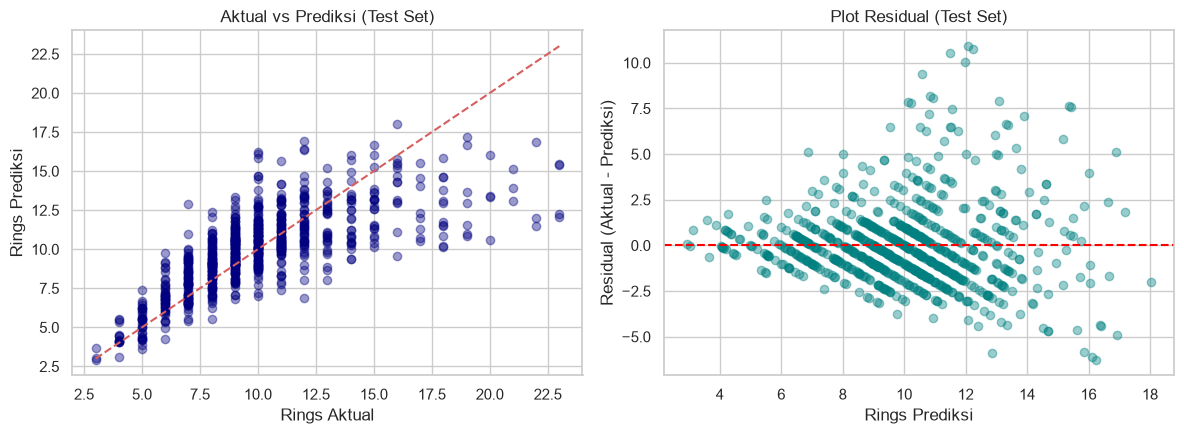

In [26]:
import joblib
from sklearn.model_selection import train_test_split

model = joblib.load("src/app/model/model.joblib")

X = df.drop(columns=["Rings"])
y = df["Rings"]
_, X_test, _, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

y_pred = model.predict(X_test)
residual = y_test - y_pred

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.4, color="navy")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Aktual vs Prediksi (Test Set)")
plt.xlabel("Rings Aktual")
plt.ylabel("Rings Prediksi")

plt.subplot(1, 2, 2)
plt.scatter(y_pred, residual, alpha=0.4, color="teal")
plt.axhline(0, color="red", linestyle="--")
plt.title("Plot Residual (Test Set)")
plt.xlabel("Rings Prediksi")
plt.ylabel("Residual (Aktual - Prediksi)")

plt.tight_layout()
plt.savefig("docs/evidence/evaluasi_test_set.png", dpi=150)
plt.show()